# Planejando Experimentos e Comparando Classificadores

Até o momento, vimos diversas formas de criar bons classificadores a partir de um conjunto de dados.

A aula de hoje foca em uma tarefa um pouco diferente, mas muito importante.

Na aula, veremos apenas uma introdução ao assunto. No fim do material, há uma série de observações importantes e leituras recomendadas.

## Pergunta de hoje

Suponha que você tenha um conjunto de dados rotulado $D = \{(\mathbf{x}_i, y_i)\}_{i = 1}^n$. Suponha também que você tenha dois algoritmos de treinamento de classificadores a sua disposição, $\mathcal{A}$ e $\mathcal{B}$.

**Qual dos dois algoritmos gera um melhor classificador para a tarefa de classificação relacionada ao conjunto de dados $D$?**

A princípio, essa parece uma pergunta simples. Basta treinar os classificadores e ver qual dos dois têm o melhor desempenho de acordo com as métricas de avaliação estudadas.

No entanto, por vários motivos, essa é uma pergunta mais complicada do que parece.

## Aleatoriedade no treinamento de um classificador

Mesmo que utilizando um mesmo algoritmo de treinamento, classificadores diferentes podem ser obtidos de um mesmo conjunto de dados.

Isso ocorre porque há aleatoriedade envolvida em várias partes do treinamento de um classificador.

Vejamos dois exemplos.

###Exemplo I - Aleatoriedade na Preparação dos Dados

O código abaixa utiliza o conjunto de dados relacionado à tarefa de reconhecimento de dígitos.

De acordo com o que já vimos, os dados são divididos em porções para treinamento e teste.

Posteriormente um KNN com $k = 50$ é treinado (escolha arbitrária) utilizando a porção dos dados retida para treinamento.

Após o treinamento, o modelo é avaliado no conjunto de teste.

In [ ]:
from sklearn.datasets import load_digits
from sklearn.metrics import classification_report
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import train_test_split

# carregando o conjunto de dados
X, y = load_digits(return_X_y = True, as_frame = True)

# dividindo os dados em conjuntos de treinamento e teste
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.3)

# Treinando um KNN com k = 50 (escolha arbitrária)
model = KNeighborsClassifier(n_neighbors = 50)
model.fit(X_train, y_train);

# Obtendo os rótulos do conjunto de teste de acordo com o modelo
y_pred = model.predict(X_test)

# Apresentando as métricas de avaliação
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       1.00      1.00      1.00        58
           1       0.76      0.95      0.84        37
           2       0.92      0.91      0.91        53
           3       0.98      0.98      0.98        54
           4       0.98      0.95      0.97        63
           5       1.00      0.95      0.97        55
           6       0.97      0.98      0.97        57
           7       0.91      1.00      0.95        52
           8       0.94      0.74      0.83        61
           9       0.89      0.96      0.92        50

    accuracy                           0.94       540
   macro avg       0.94      0.94      0.94       540
weighted avg       0.94      0.94      0.94       540



Pode-se perceber que, se executarmos o código acima mais de uma vez, os resultados serão diferentes dos apresentados.

Isso ocorre uma vez que a divisão em conjuntos de treinamento e teste (i.e., método `train_test_split`) possui uma componente aleatória.

Em outras palavras, os conjuntos de treinamento e teste mudam em diferentes execuções. Com isso, os resultados possuem uma certa variação.

Abaixo, repetimos o mesmo experimento 10 vezes. Para cada uma das repetições, o $F_1$-score do classificador é apresentado.

In [ ]:
from sklearn.metrics import f1_score

for i in range(10):
  X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.3)
  model = KNeighborsClassifier(n_neighbors = 50)
  model.fit(X_train, y_train);
  y_pred = model.predict(X_test)
  print('i = %d, f1 Score = %.4f' % (i, f1_score(y_test, y_pred, average = 'weighted')))

i = 0, f1 Score = 0.9281
i = 1, f1 Score = 0.9366
i = 2, f1 Score = 0.9388
i = 3, f1 Score = 0.9373
i = 4, f1 Score = 0.9162
i = 5, f1 Score = 0.9327
i = 6, f1 Score = 0.9439
i = 7, f1 Score = 0.9366
i = 8, f1 Score = 0.9354
i = 9, f1 Score = 0.9253


Novamente, pode-se perceber as variações no $F_1$-score nas diferentes execuções.

###Exemplo II - Aleatoriedade no Treinamento

O código abaixo executa um experimento similar. As modificações são:
1. A divisão dos dados em conjuntos de treinamento e teste é fixa (uma vez que `random_state = 42`);
2. Um classificador de Floresta Aleatória (com a escolha arbitrária de 10 árvores) é utilizado.

In [ ]:
from sklearn.ensemble import RandomForestClassifier

for i in range(10):
  X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.3, random_state = 42)
  model = RandomForestClassifier(n_estimators = 10)
  model.fit(X_train, y_train);
  y_pred = model.predict(X_test)
  print('i = %d, f1 Score = %.4f' % (i, f1_score(y_test, y_pred, average = 'weighted')))

i = 0, f1 Score = 0.9404
i = 1, f1 Score = 0.9649
i = 2, f1 Score = 0.9534
i = 3, f1 Score = 0.9570
i = 4, f1 Score = 0.9517
i = 5, f1 Score = 0.9592
i = 6, f1 Score = 0.9704
i = 7, f1 Score = 0.9483
i = 8, f1 Score = 0.9534
i = 9, f1 Score = 0.9552


Novamente, pode-se perceber que os $F_1$-scores de execuções diferentes são diferentes.

Nesse caso, como a divisão do conjunto de dados é sempre a mesma, as variações que ocorrem nos resultados vêm do fato de que o classificador utilizado possui componentes aleatórias.

Por fim, se executarmos o experimento acima sem fixar a divisão dos conjuntos de treinamento e teste, temos que as variações se combinam.

In [ ]:
from sklearn.ensemble import RandomForestClassifier

for i in range(10):
  X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.3)
  model = RandomForestClassifier(n_estimators = 10)
  model.fit(X_train, y_train);
  y_pred = model.predict(X_test)
  print('i = %d, f1 Score = %.4f' % (i, f1_score(y_test, y_pred, average = 'weighted')))

i = 0, f1 Score = 0.9373
i = 1, f1 Score = 0.9234
i = 2, f1 Score = 0.9501
i = 3, f1 Score = 0.9630
i = 4, f1 Score = 0.9368
i = 5, f1 Score = 0.9344
i = 6, f1 Score = 0.9552
i = 7, f1 Score = 0.9518
i = 8, f1 Score = 0.9499
i = 9, f1 Score = 0.9385


### Pergunta

O Código abaixo treina duas Florestas Aleatórias no mesmo conjunto de treinamento e realiza a avaliação no mesmo conjunto de teste.

É possível afirmar que o Classificador 2 é melhor que o Classificador 1 para o conjunto de dados referente ao reconhecimento de dígitos?

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.3)

# Clssificador 1
model = RandomForestClassifier(n_estimators = 10)
model.fit(X_train, y_train);
y_pred = model.predict(X_test)
print('Classificador 1 - 10 Árvores, f1 Score = %.4f' % (f1_score(y_test, y_pred, average = 'weighted')))

# Classificador 2
model = RandomForestClassifier(n_estimators = 20)
model.fit(X_train, y_train);
y_pred = model.predict(X_test)
print('Classificador 2 - 20 Árvores, f1 Score = %.4f' % (f1_score(y_test, y_pred, average = 'weighted')))

Classificador 1 - 10 Árvores, f1 Score = 0.9333
Classificador 2 - 20 Árvores, f1 Score = 0.9576


Com base no que vimos até o momento, mesmo que o $F_1$-Score do Classificador 2 seja maior que o $F_1$-Score do Classificador 1, não é possível afirmar que um seja melhor que o outro.

O motivo é simples! Com a execução de um único experimento, não é possível afirmar que as diferenças são devidas a um classificador ser melhor do que o outro ou às componentes aleatórias do processo de treinamento.

### Ideia

Bom, se o "problema" vem da aleatoriedade, uma maneira de resolvê-lo é se livrando dela!

O código abaixo ilustra uma forma de fazer isso, fixando os estados iniciais dos geradores de números pseudoaleatórios.

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.3, random_state = 42)

# Clssificador 1
model = RandomForestClassifier(n_estimators = 10, random_state = 42)
model.fit(X_train, y_train);
y_pred = model.predict(X_test)
print('Classificador 1 - 10 Árvores, f1 Score = %.4f' % (f1_score(y_test, y_pred, average = 'weighted')))

Classificador 1 - 10 Árvores, f1 Score = 0.9438


Apesar de a solução acima garantir que os resultados do experimento serão sempre os mesmos, ela não é uma boa solução para o nosso problema.

Fixar os estados iniciais dos geradores de número pseudoaleatórios é uma ferramenta interessante para depuração e comparação de experimentos em casos bem específicos e planejados.

**No caso geral, essa estratégia não é interessante por um motivo simples**. A escolha do estado inicial dos geradores (e.g., o valor ``42'') é arbitrária.

Em outras palavras, se mudássemos os estados iniciais, poderíamos ter resultados e conclusões diferentes.

##Estratégia I - Repetição dos Experimentos

Para mitigar as complicações das situações elencadas acima, é recomendado que o processo de treinamento e avaliação dos classificadores seja repetido várias vezes.

Com isso, pode-se observar o comportamento médio e a variabilidade dos resultados.

Abaixo, um exemplo. Observe que em cada iteração, a mesma divisão dos dados é utilizado. Sempre que possível, é indicado proceder dessa forma.

In [ ]:
import pandas as pd

scores = []

for i in range(30):

  X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.3)

  # Clssificador 1
  model = RandomForestClassifier(n_estimators = 10)
  model.fit(X_train, y_train);
  y_pred = model.predict(X_test)
  score1 = f1_score(y_test, y_pred, average = 'weighted')


  # Classificador 2
  model = RandomForestClassifier(n_estimators = 20)
  model.fit(X_train, y_train);
  y_pred = model.predict(X_test)
  score2 = f1_score(y_test, y_pred, average = 'weighted')

  scores.append([score1, score2])

df = pd.DataFrame(scores, columns = ['Classificador 1', 'Classificador 2'])

Ao observar as médias e desvios padrões dos classificadores, há uma indicação de que o Classificador 2 é melhor que o Classificador 1 (com respeito à medida $F_1$-Score).

Esse é o caso uma vez que a média para o Classificador 2 é superior à média para o Classificador 1 e as variabilidades são muito pequenas.

In [ ]:
df.describe()

,Classificador 1,Classificador 2
count,30.000000,30.000000
mean,0.940286,0.963263
std,0.010110,0.008162
min,0.917821,0.944522
25%,0.936040,0.957643
50%,0.940481,0.962973
75%,0.945280,0.969825
max,0.964783,0.981483


Os resultados das repetições podem ser visualizados de diversas maneiras. A seguir os *box-plots* dos $F_1$-Scores.


Por esse gráfico, pode-se perceber que, com alta probabilidade, o $F_1$-Score do Classificador 2 é superior ao $F_1$-Score do Classificador 1.

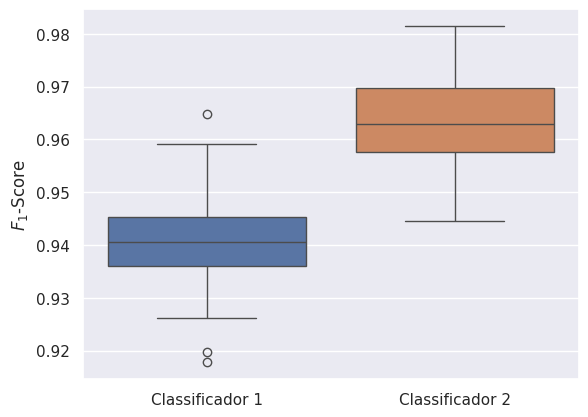

In [ ]:
#@title

import seaborn as sns
import matplotlib.pyplot as plt
sns.set()

sns.boxplot(data = df)
plt.ylabel(r'$F_1$-Score');

Uma segunda visualização é por meio de gráficos de barra.

A biblioteca ``seaborn`` permite a construção de gráficos de barra para valores médios e também Intervalos de Confiança (traços verticais nas barras).

No caso da Figura, temos o Intervalo de Confiança de 95% computado pela biblioteca ``seaborn``.

Pode-se perceber que a média dos $F_1$-Scores do Classificador 2 é superior à média do Classificador 1. Além disso, não há sobreposição dos Intervalos de Confiança.

Esse fato é uma indicação forte de que o Classificador 2 tem desempenho superior ao Classificador 1 para a tarefa referente ao problema de classificação no conjunto de dados de reconhecimento de dígitos.

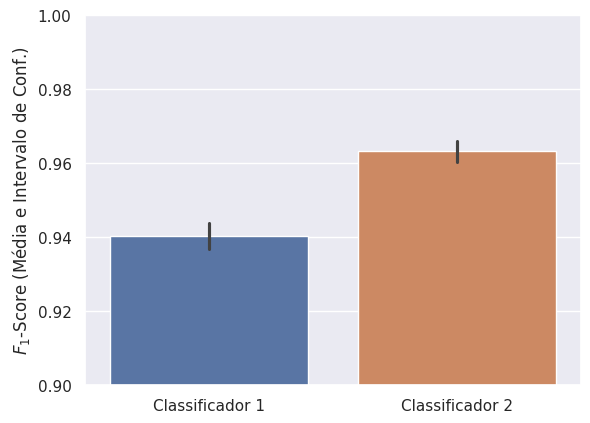

In [ ]:
#@title

import seaborn as sns
import matplotlib.pyplot as plt
sns.set()

sns.barplot(data = df)
plt.ylim((0.9, 1))
plt.ylabel(r'$F_1$-Score (Média e Intervalo de Conf.)');

#### Quantas repetições?

Para o cálculo de médias e cômputo de Intervalos de Confiança, recomenda-se que os experimentos sejam repetidos cerca de 30 vezes (como no exemplo).

No entanto, nem sempre isso é possível, devido ao custo computacional da tarefa de treinamento ou ao tamanho do conjunto de dados.

##Estratégia II - Testes de Hipótese



Uma maneira de prover mais evidências de que um classificador é melhor do que outro, para uma determinada tarefa, é utilizando Testes de Hipótese.

Teste de Hipótese é uma ferramenta advinda da Estatística. Está fora do escopo desse material explicar como testes são construídos e seu funcionamento em geral.

Aqui, vamos nos ater ao mínimo necessário para o objetivo de comparar dois classificadores.

No exemplo anterior, como o Classificador 1 e o Classificador 2 foram sempre treinados e avaliados nos mesmos conjuntos de treinamento e teste, podemos utilizar testes para dados **pareados**.

#### Teste $t$ pareado

O [Teste $t$ Pareado](https://en.wikipedia.org/wiki/Student%27s_t-test) possui os seguintes pressupostos:
1. Os pares são independentes entre si. Ou seja, cada repetição do experimento foi executada de maneira independente das demais.
2. Cada par representa o mesmo item observado em duas diferentes condições. Ou seja, algoritmos diferentes foram usados nos mesmos subconjuntos de treinamento e teste.
3. A distribuição das diferenças, em cada par, possui uma distribuição normal.


O Teste tem a **hipótese nula** de que a diferença entre os elementos de cada par tem média 0.

No nosso contexto, a **hipótese nula** significa que os dois classificadores não possuem diferença significativa.

O Código abaixo mostra como o teste pode ser executado utilizando a biblioteca [``scipy``](https://docs.scipy.org/doc/scipy-1.15.0/reference/generated/scipy.stats.ttest_rel.html).

In [ ]:
from scipy import stats

r = stats.ttest_rel(df['Classificador 1'], df['Classificador 2'], alternative = 'less')
r.pvalue

7.415159130898385e-13

O resultado de um teste de hipótese é, comumente, um *p-valor*. Essa quantidade indica a probabilidade de se obter um teste com resultado pelo menos tão extremo quanto o resultado obtido com os dados, assumindo que a hipótese nula é verdadeira.

Assim, um *p-valor* pequeno indica que o resultado obtido com os dados analisados tem pouca probabilidade de ser compatível com a hipótese nula.

Geralmente, estabelece-se o limiar de 0.05. Em outras palavras e, simplificando, se $p < 0.05$, rejeita-se a hipótese nula do teste.

No exemplo acima, rejeita-se a hipótese nula de que a diferença entre os classificadores (em cada execução) possui média zero. Em outras palavras, os dados demostram que o $F_1$-Score do Classificador 1 é, de fato, menor do que o do Classificador 2 para o problema posto pelo conjunto de dados analisado.

**Importante:**
1. O teste $t$ pareado assume que os dados são provenientes de distribuições normais. Veja que nós não mostramos ser esse o caso.

2. Mesmo que os dados não sejam normalmente distribuídos, é comum utilizar esse teste quando o número de execuções do experimento é grande (e.g., maior que 30).

3. Caso não seja possível verificar a normalidade dos dados ou executar o experimento várias vezes, o teste $t$ pareado não é recomendado. Nesse caso, recomenda-se o teste de *Wilcoxon*.

### Teste de *Wilcoxon*

O teste de *Wilcoxon* é similar ao teste *t* pareado. No entanto, ele não possui o pressuposto da normalidade dos dados.

A biblioteca ``scipy`` também possui funcionalidades para utilizar esse teste. Um exemplo abaixo.

In [ ]:
from scipy import stats

r = stats.wilcoxon(df['Classificador 1'], df['Classificador 2'], alternative = 'less')
r.pvalue

1.862645149230957e-09

Novamente, com o *p valor* acima, o teste indica que o Classificador 2 é melhor que o Classificador 1.

### Mais um Exemplo

A título de exemplo, o experimento anterior é repetido. No entanto, utilizamos o Classificador 1 e o Classificador 2 com 50 e 60 Árvores de Decisão, respectivamente.

In [ ]:
import pandas as pd

scores = []

for i in range(30):

  X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.3)

  # Clssificador 1
  model = RandomForestClassifier(n_estimators = 50)
  model.fit(X_train, y_train);
  y_pred = model.predict(X_test)
  score1 = f1_score(y_test, y_pred, average = 'weighted')


  # Classificador 2
  model = RandomForestClassifier(n_estimators = 60)
  model.fit(X_train, y_train);
  y_pred = model.predict(X_test)
  score2 = f1_score(y_test, y_pred, average = 'weighted')

  scores.append([score1, score2])

df = pd.DataFrame(scores, columns = ['Classificador 1', 'Classificador 2'])

In [ ]:
r = stats.ttest_rel(df['Classificador 1'], df['Classificador 2'])
r.pvalue

0.4231856363148132

In [ ]:
r = stats.wilcoxon(df['Classificador 1'], df['Classificador 2'])
r.pvalue

0.40449450351297855

Pelos resultados acima, como os *p valores* não são pequenos, temos que não podemos rejeitar a hipótese nula dos testes.

Com isso, não é possível dizer que o desempenho do Classificador 2 é melhor do que o do Classificador 1.

## Considerações importantes

O planejamento de experimentos para a comparação de classificadores não é uma tarefa trivial. Nesse material, mostramos situações e exemplos simples de como essa tarefa pode ser realizada.

Podemos utilizar o que vimos hoje para fazer a comparação quando tivermos mais do que dois classificadores? A comparação entre pares é possível, mas para tirar uma conclusão única de múltiplos testes, é necessário realizar uma correção nos *p valores*. Veja, por exemplo, a correção de [Bonferroni](https://en.wikipedia.org/wiki/Bonferroni_correction).

E se quisermos, por exemplo, estender o que vimos para vários classificadores e vários conjuntos de dados distintos? Nesse caso, recomenda-se o estudo da [ANOVA](https://en.wikipedia.org/wiki/Analysis_of_variance), do teste de [Kruskal-Wallis](https://en.wikipedia.org/wiki/Kruskal%E2%80%93Wallis_test) e do teste de [Friedman](https://en.wikipedia.org/wiki/Friedman_test).

O artigo científico [Statistical Comparisons of Classifiers
over Multiple Data Sets](https://www.jmlr.org/papers/volume7/demsar06a/demsar06a.pdf) apresenta uma excelente discussão sobre a problemática de comparação de classificadores. A leitura é um pouco mais avançada, mas altamente recomendada.

Em resumo, antes de aplicar testes de hipótese, é necessário conhecer os dados e os objetivos. Um planejamento adequado e que respeite os pressupostos dos testes são essenciais!